# Домашнее задание: Прогнозирование стоимости автомобиля
**Курс:** AI Applications Using Python  
**Модуль:** AI 07 — Машинное обучение (Регрессия и конвейеры предобработки)  
**Цель:** построить модель, которая прогнозирует стоимость подержанного автомобиля по его характеристикам с использованием `Pipeline` и `ColumnTransformer`.

---

## 1. Первичный анализ данных
**Задачи:**
- Загрузить данные из файла `Used_Cars_Homework.csv` и вывести первые 10 строк.
- Определить количество строк и столбцов, типы данных и количество пропусков.
- Вывести описательную статистику числовых столбцов.
- Найти минимальную, максимальную и среднюю стоимость автомобиля.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Загрузка данных
df = pd.read_csv('Used_Cars_Homework.csv')
print(f"Размер датасета: {df.shape}")

# Первые 10 строк
display(df.head(10))

# Пропуски и типы данных
print("Пропуски в данных:")
print(df.isna().sum())

# Описательная статистика
display(df.describe().round(2))

# Мин, макс и средняя стоимость
print("\nСтатистика стоимости (price_azn):")
print(f"Минимум: {df['price_azn'].min():,.2f} AZN | Максимум: {df['price_azn'].max():,.2f} AZN | Среднее: {df['price_azn'].mean():,.2f} AZN | Медиана: {df['price_azn'].median():,.2f} AZN")

Размер датасета: (300, 9)
Пропуски в данных:
age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64

Статистика стоимости (price_azn):
Минимум: 3,805.00 AZN | Максимум: 51,396.00 AZN | Среднее: 27,806.57 AZN | Медиана: 27,458.50 AZN


---
## 2. Визуализация
Построим 4 графика с подписями осей, заголовками и краткими выводами:
1. Гистограмма распределения стоимости.
2. Диаграмма зависимости стоимости от пробега.
3. Диаграмма зависимости стоимости от возраста.
4. Столбчатая диаграмма средней стоимости по маркам.

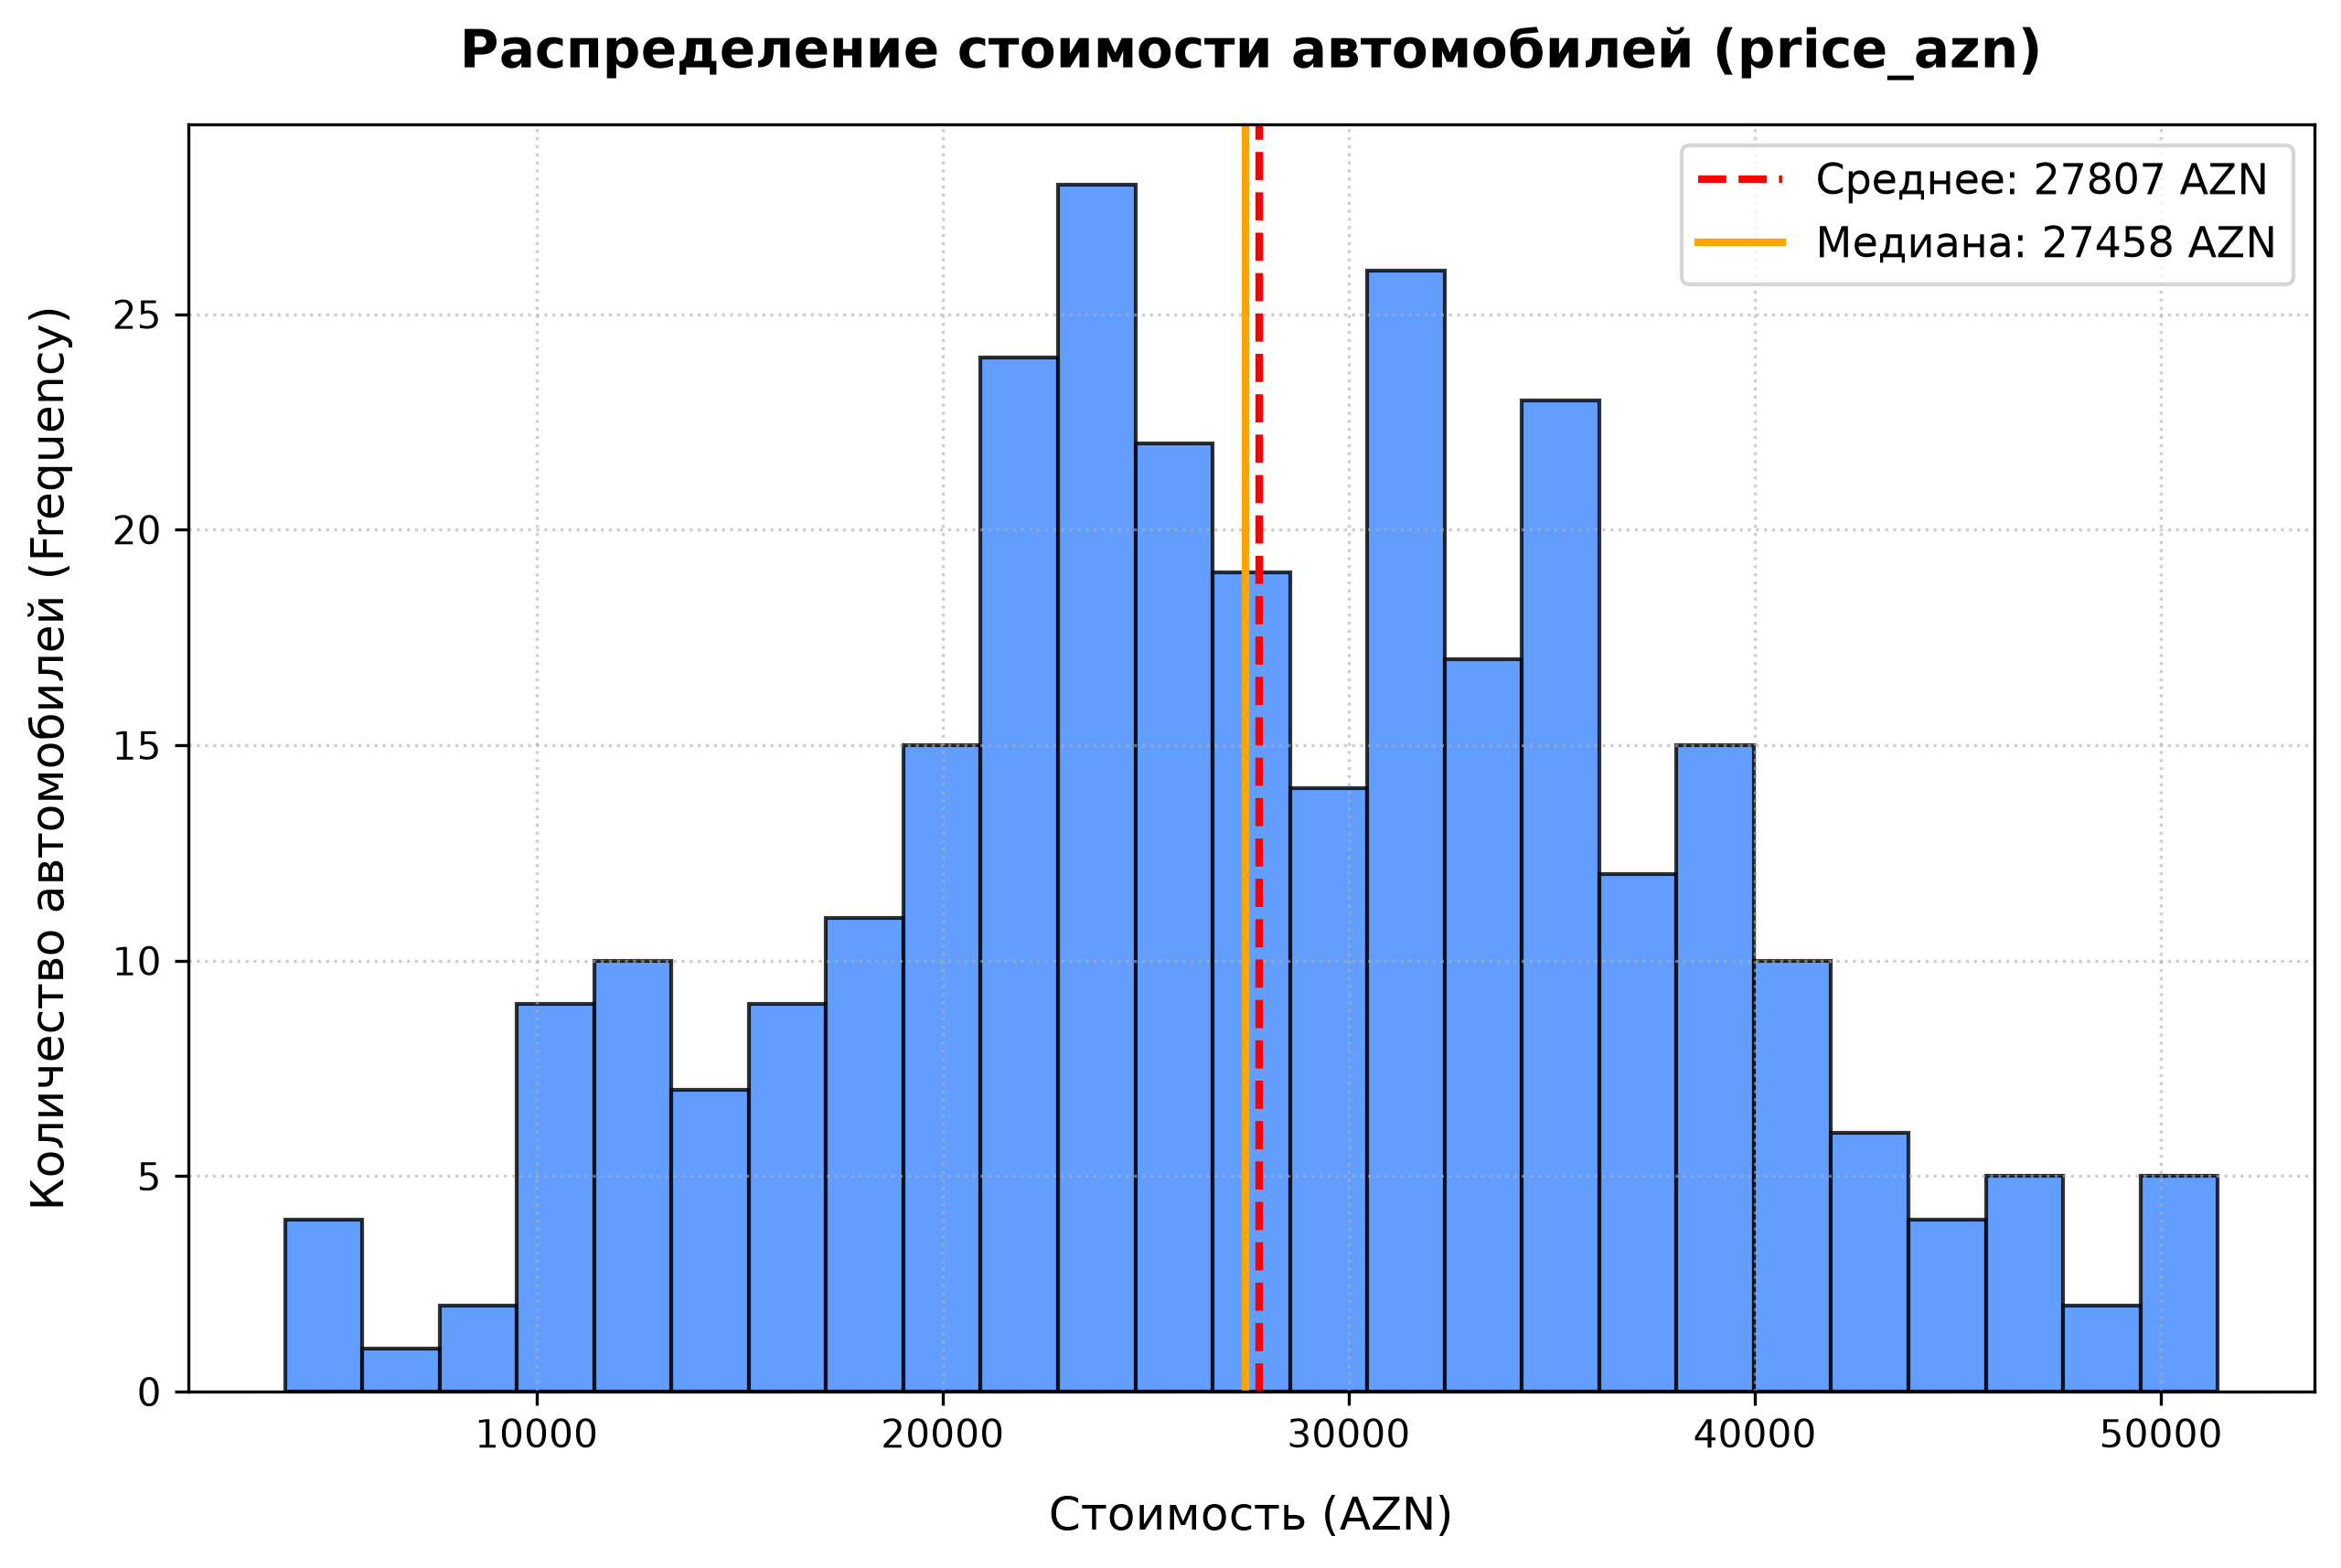

In [2]:
# 2.1. Гистограмма распределения стоимости
plt.figure(figsize=(10, 6))
plt.hist(df['price_azn'], bins=25, color='#3a86ff', edgecolor='black', alpha=0.8)
plt.axvline(df['price_azn'].mean(), color='red', linestyle='--', linewidth=2, label=f"Среднее: {df['price_azn'].mean():.0f} AZN")
plt.axvline(df['price_azn'].median(), color='orange', linestyle='-', linewidth=2, label=f"Медиана: {df['price_azn'].median():.0f} AZN")
plt.title('Распределение стоимости автомобилей (price_azn)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Стоимость (AZN)', fontsize=12)
plt.ylabel('Количество автомобилей', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

> **Вывод по графику 1:** Распределение цен унимодальное, близко к симметричному нормальному с легким смещением вправо. Основная масса подержанных автомобилей продается в ценовом диапазоне от 15 000 до 35 000 AZN.

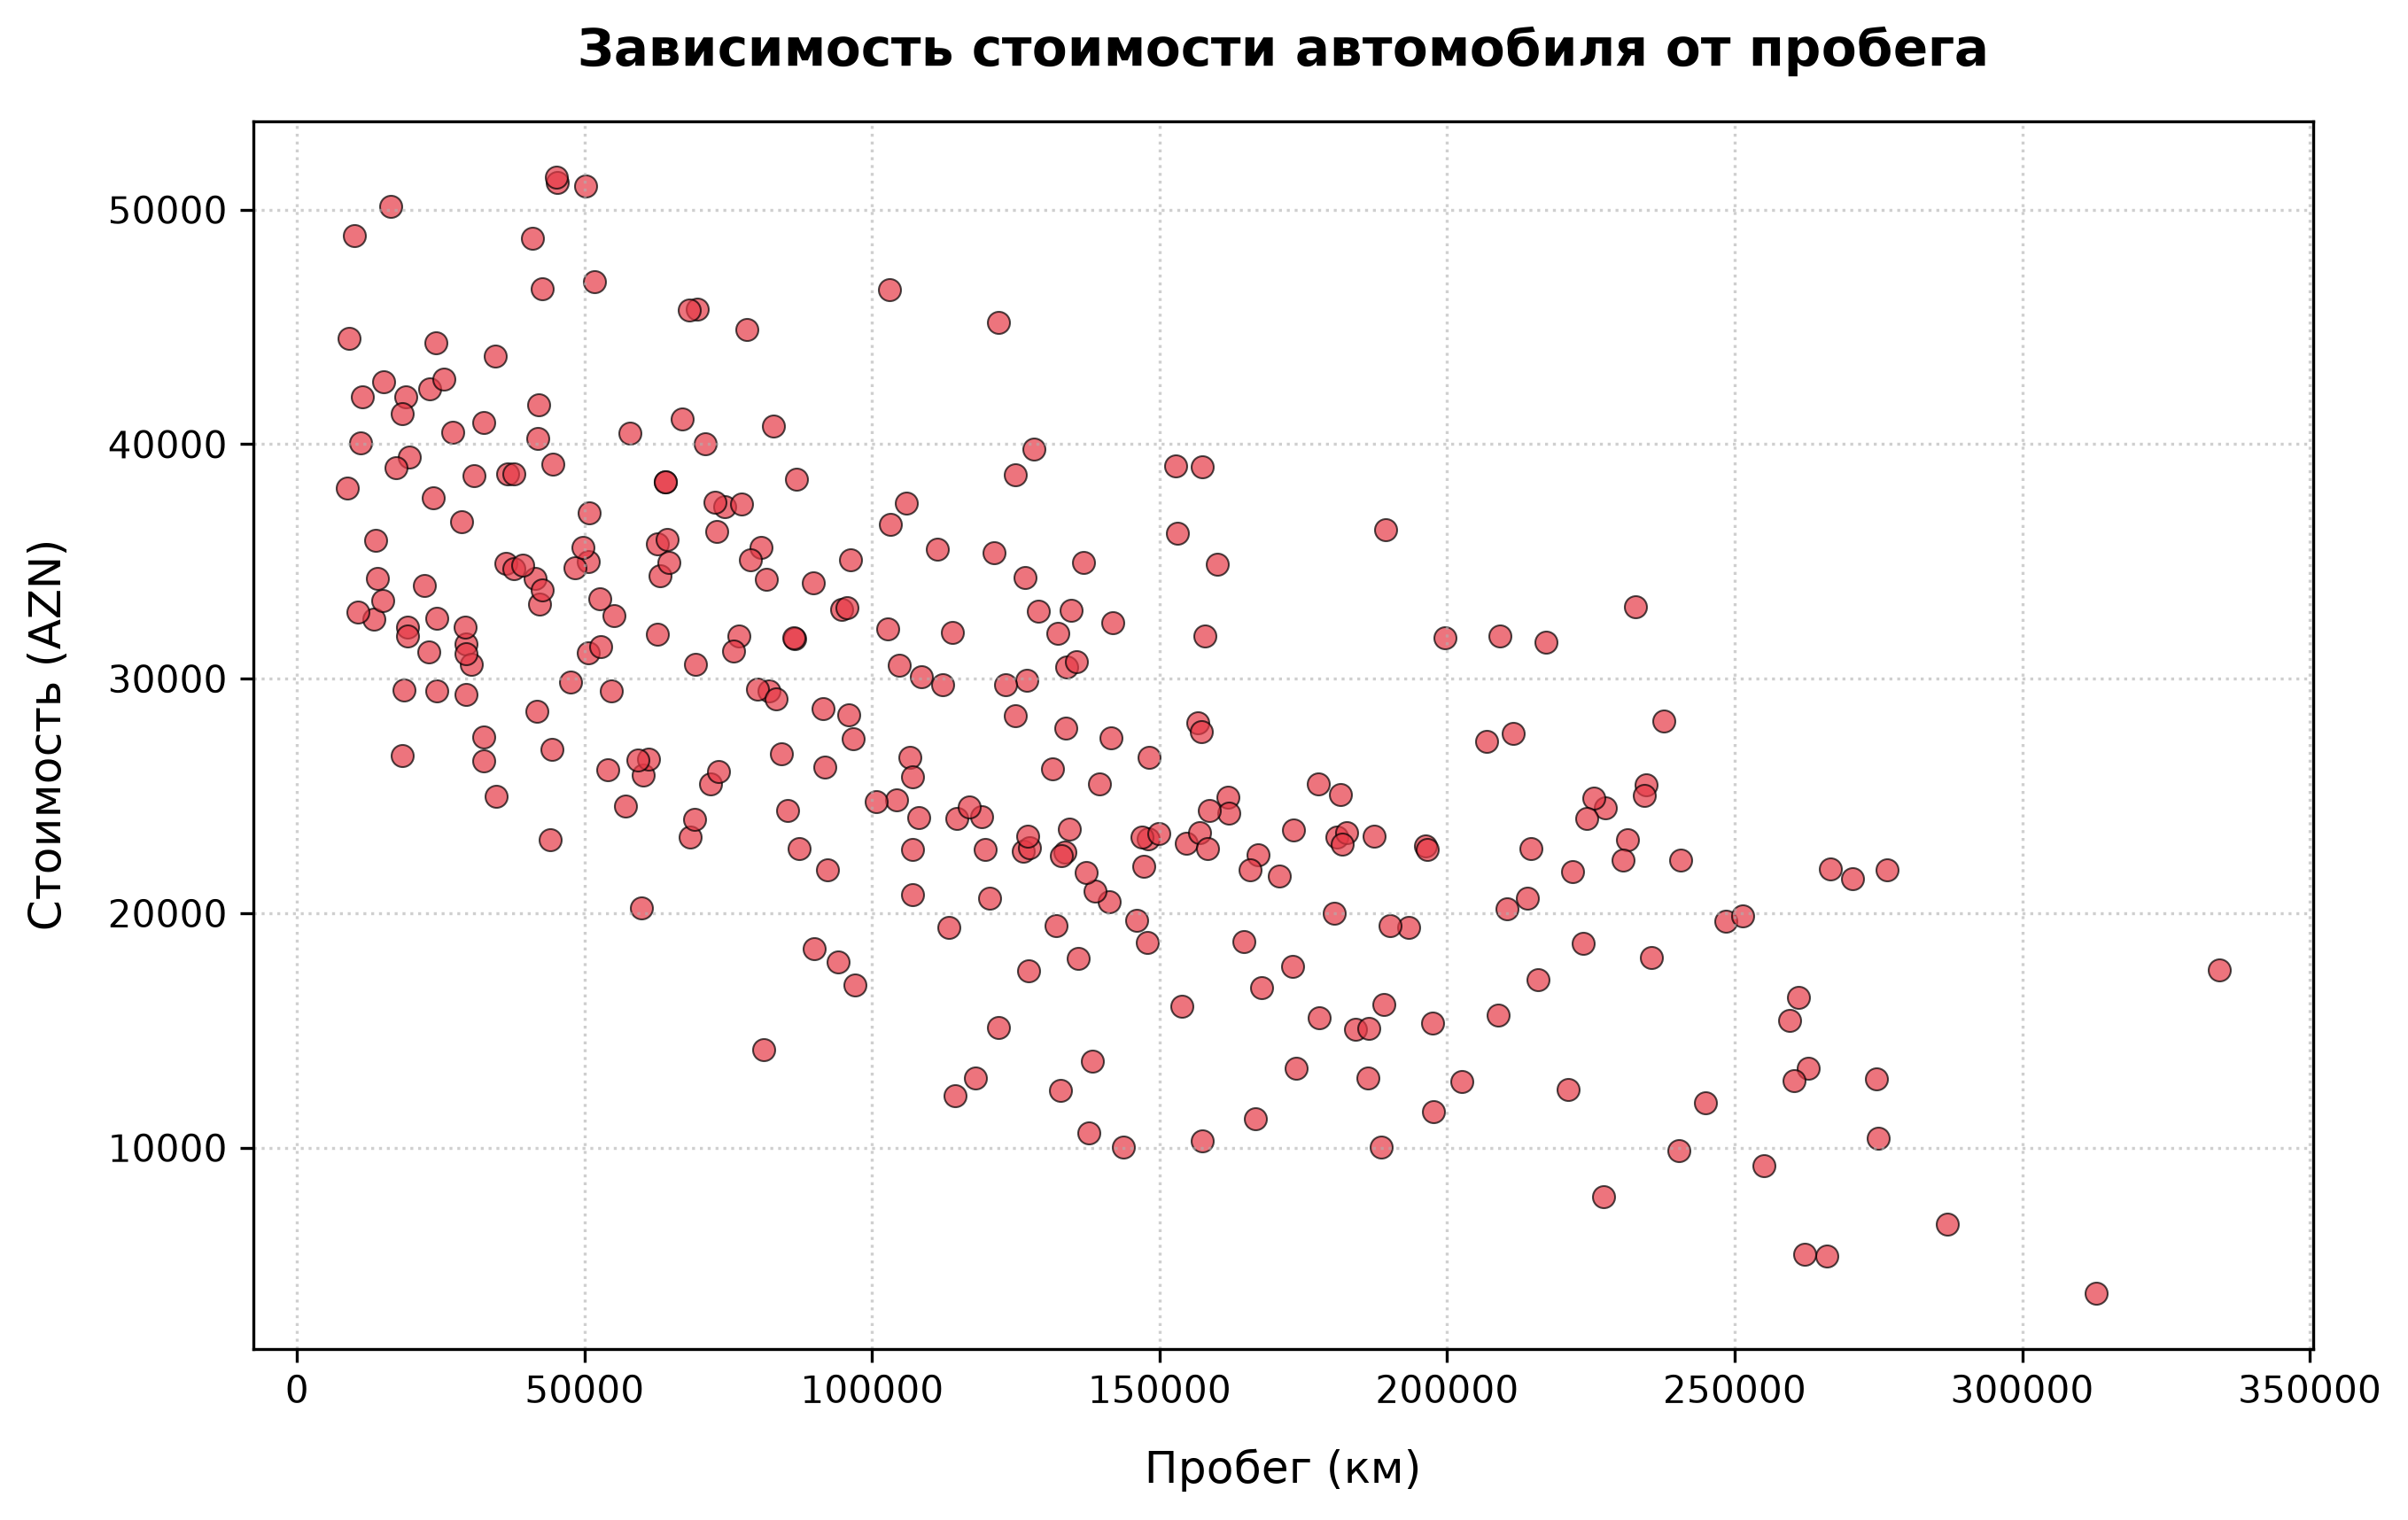

In [3]:
# 2.2. Зависимость стоимости от пробега
plt.figure(figsize=(10, 6))
clean_m = df.dropna(subset=['mileage_km'])
plt.scatter(clean_m['mileage_km'], clean_m['price_azn'], color='#e63946', alpha=0.7, edgecolors='black', linewidths=0.5)
plt.title('Зависимость стоимости автомобиля от пробега', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Пробег (км)', fontsize=12)
plt.ylabel('Стоимость (AZN)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

> **Вывод по графику 2:** Прослеживается выраженная отрицательная зависимость: чем выше пробег автомобиля, тем ниже его рыночная стоимость. Автомобили с пробегом свыше 250 000 км редко оцениваются выше 15 000 AZN.

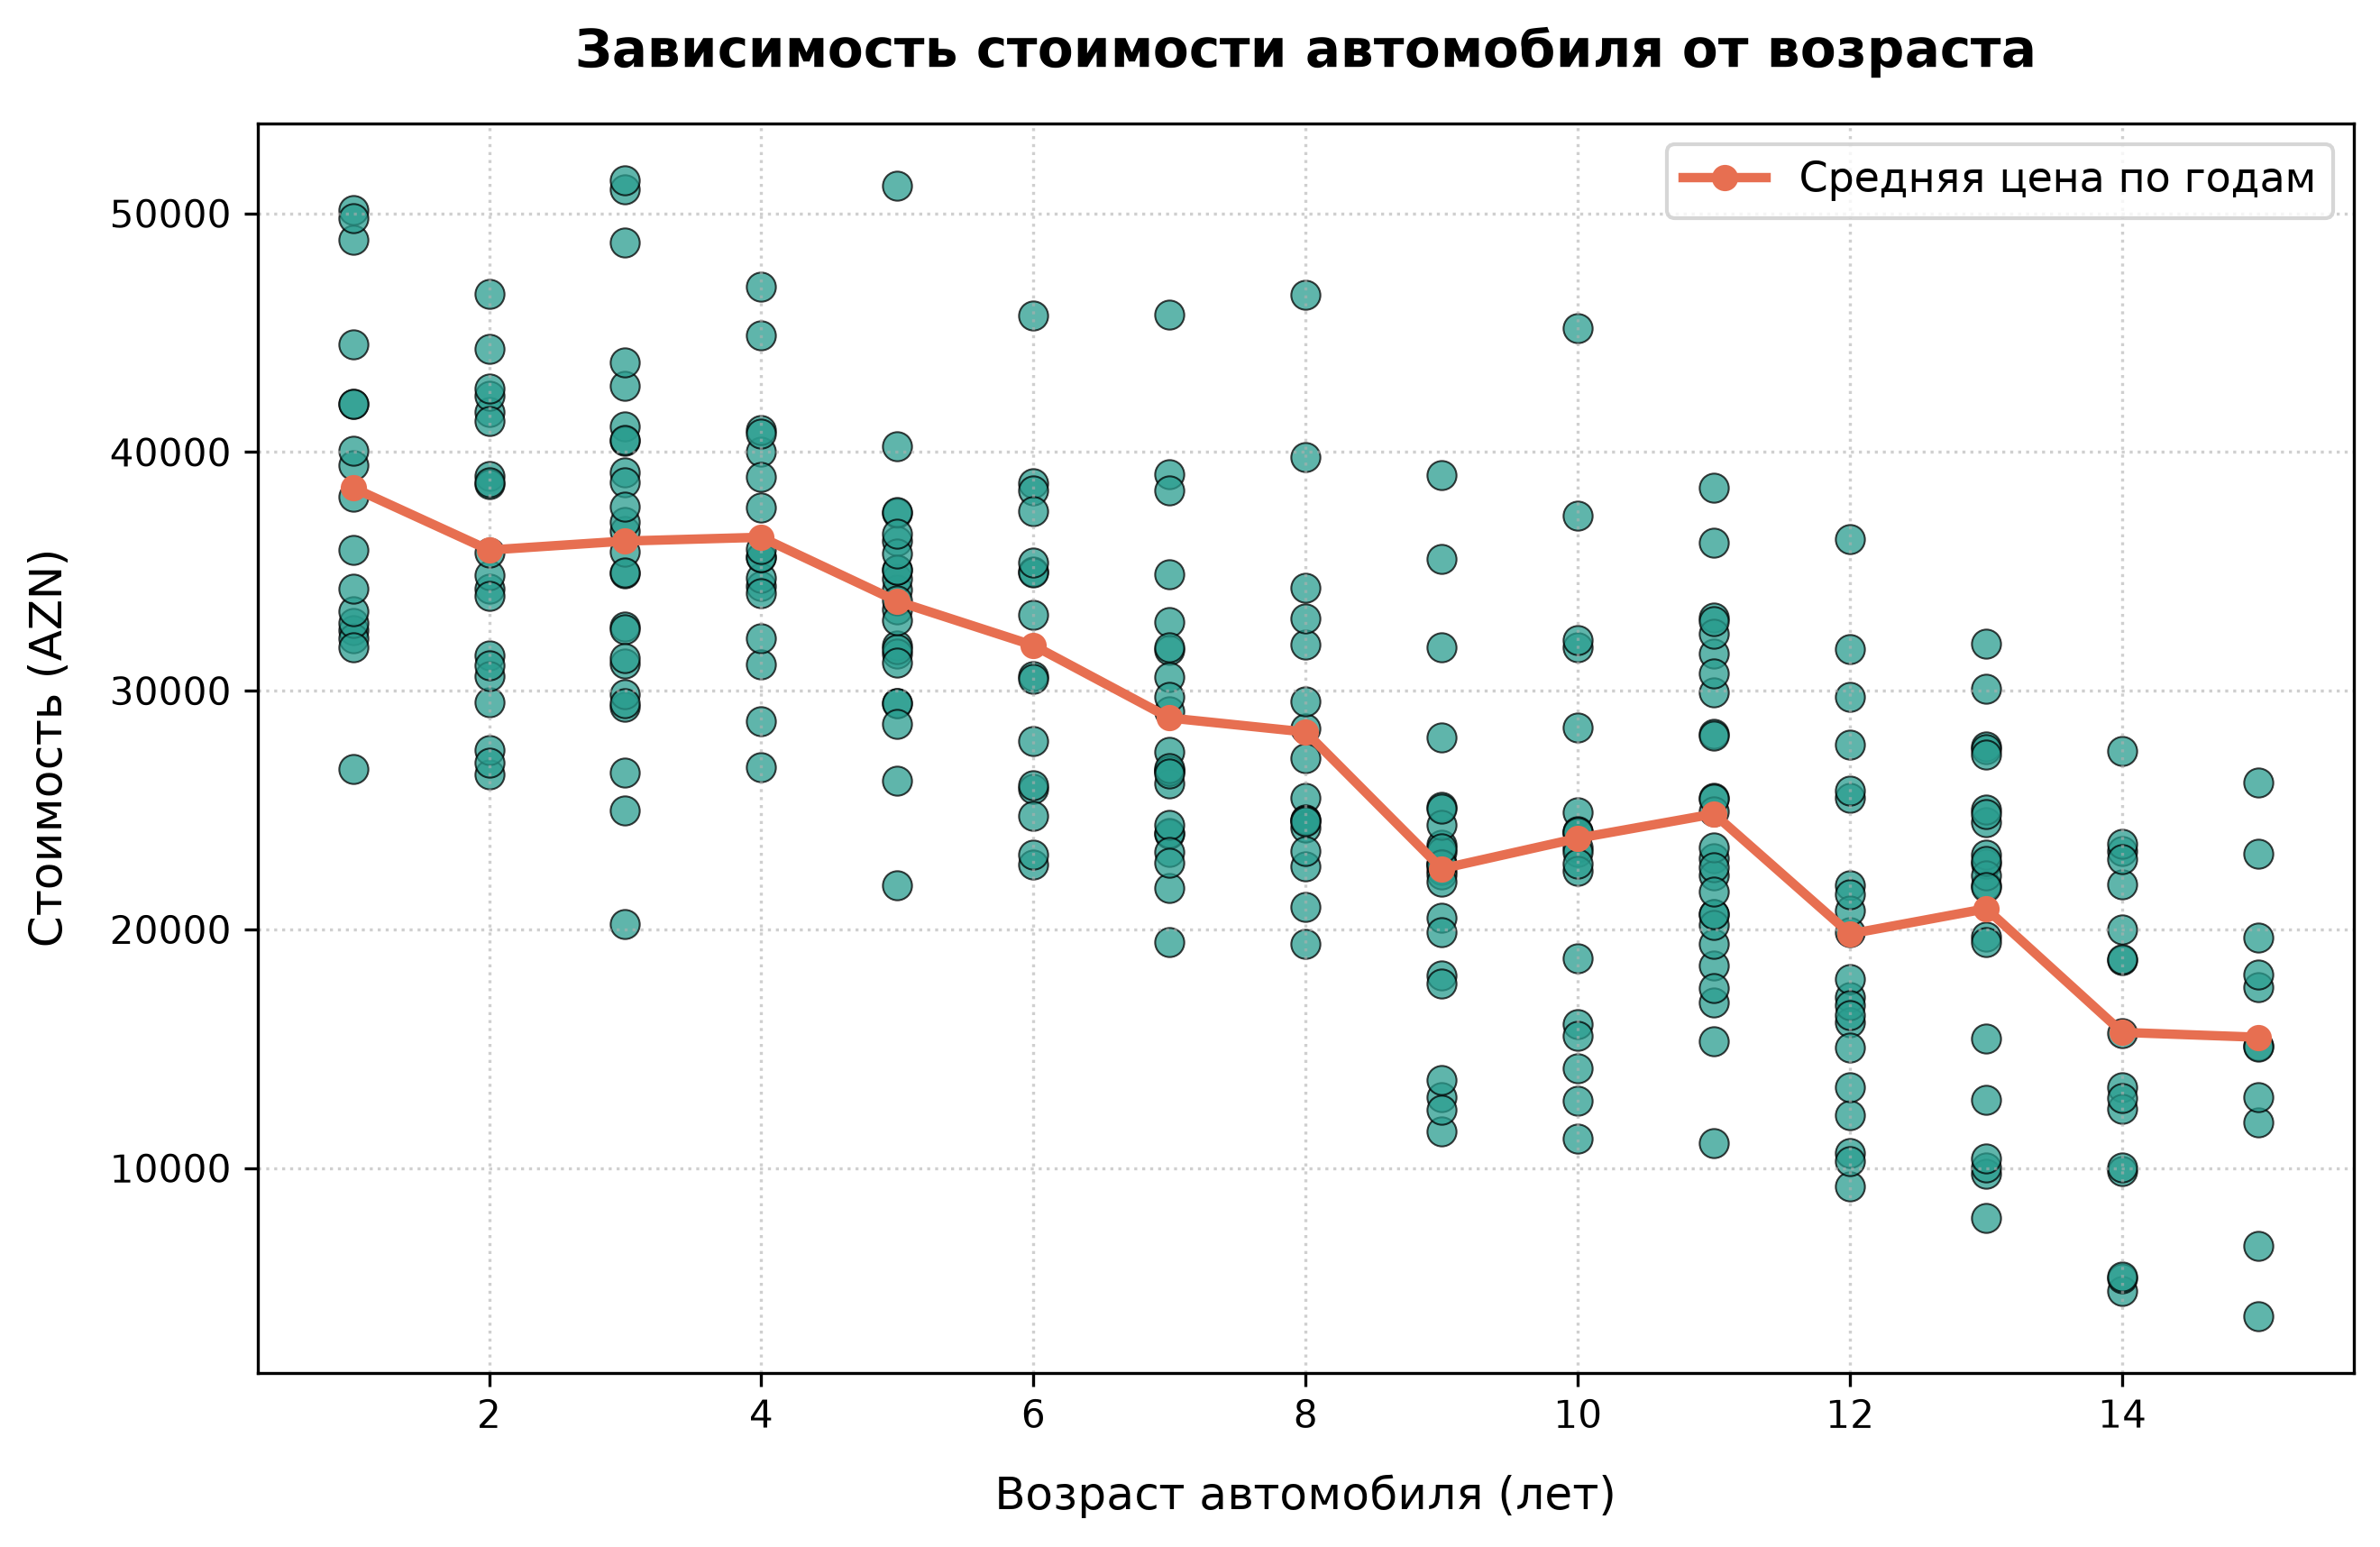

In [4]:
# 2.3. Зависимость стоимости от возраста
plt.figure(figsize=(10, 6))
plt.scatter(df['age_years'], df['price_azn'], color='#2a9d8f', alpha=0.75, s=60, edgecolors='black', linewidths=0.5)
mean_by_age = df.groupby('age_years')['price_azn'].mean()
plt.plot(mean_by_age.index, mean_by_age.values, color='#e76f51', linestyle='-', linewidth=2.5, marker='o', label='Средняя цена по годам')
plt.title('Зависимость стоимости автомобиля от возраста', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Возраст автомобиля (лет)', fontsize=12)
plt.ylabel('Стоимость (AZN)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

> **Вывод по графику 3:** Возраст автомобиля является мощнейшим фактором амортизации: новые автомобили (1-3 года) стоят в среднем 35 000 - 45 000 AZN, а к 12-15 годам эксплуатации их стоимость снижается до 10 000 - 15 000 AZN.

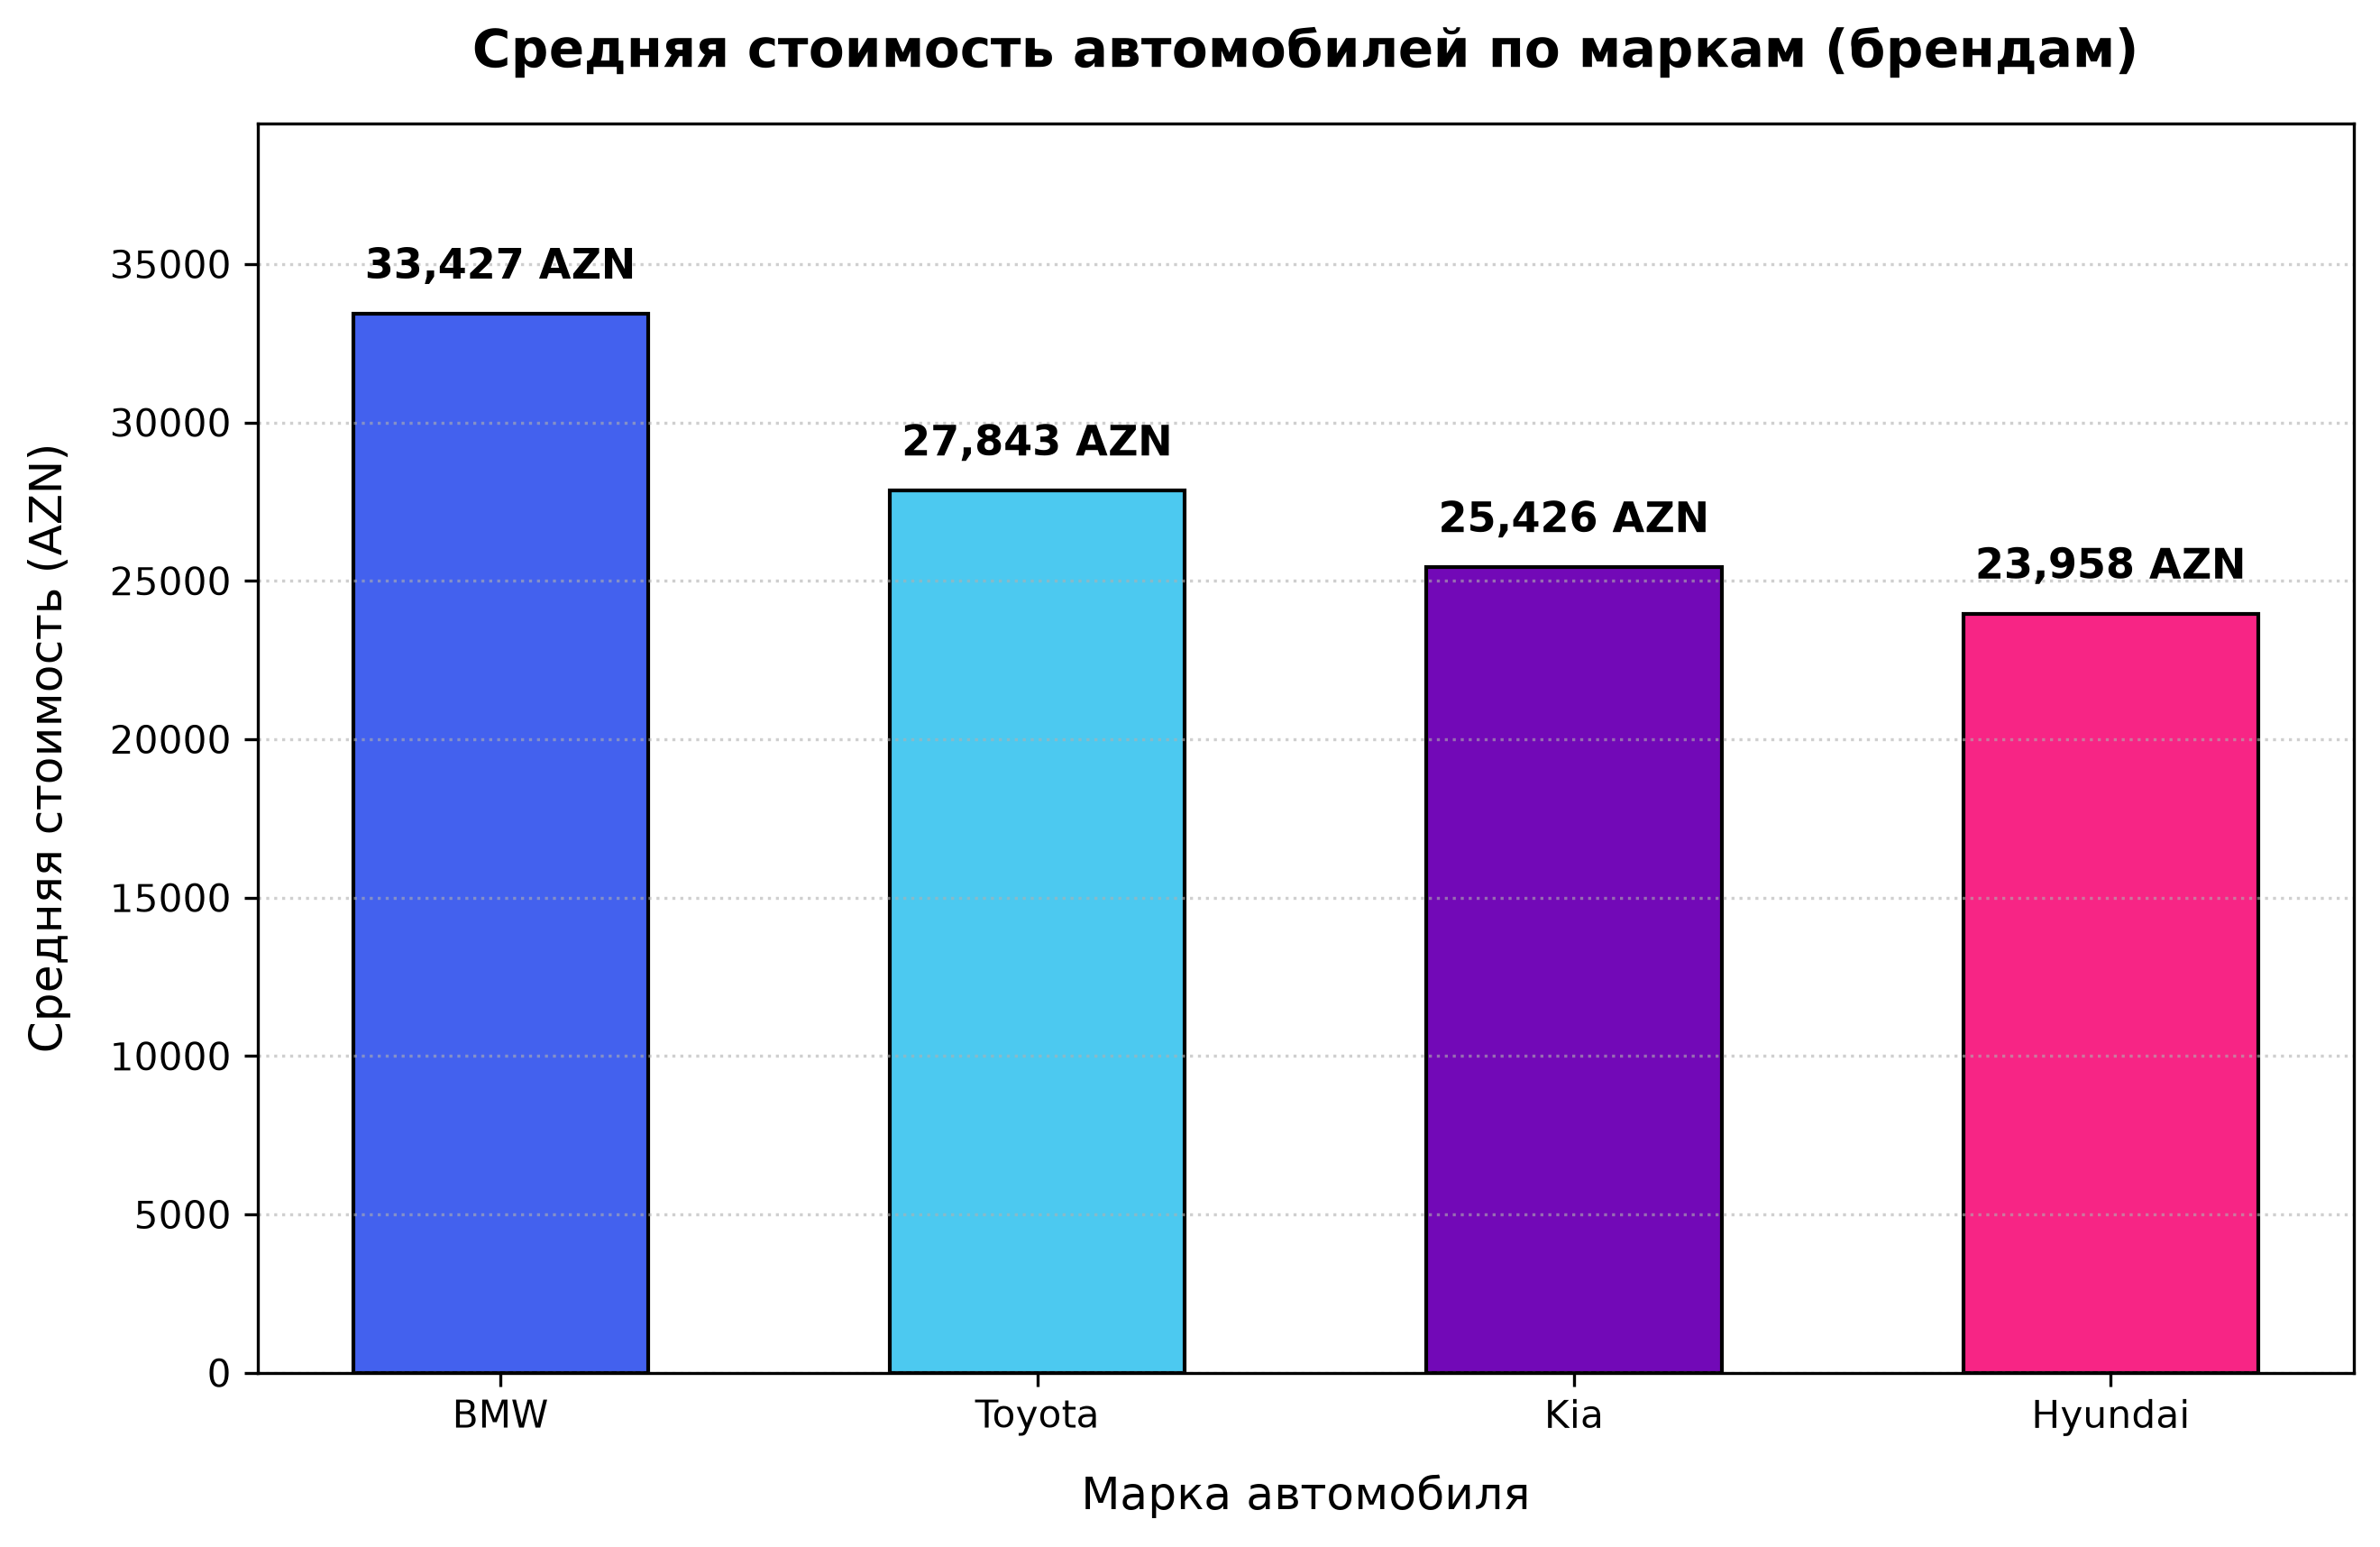

In [5]:
# 2.4. Столбчатая диаграмма средней стоимости по маркам
plt.figure(figsize=(10, 6))
brand_means = df.groupby('brand')['price_azn'].mean().sort_values(ascending=False)
bars = plt.bar(brand_means.index, brand_means.values, color=['#4361ee', '#4cc9f0', '#7209b7', '#f72585'], edgecolor='black', width=0.55)
plt.title('Средняя стоимость автомобилей по маркам', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Марка автомобиля', fontsize=12)
plt.ylabel('Средняя стоимость (AZN)', fontsize=12)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.ylim(0, brand_means.max() * 1.18)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, h + 800, f'{h:,.0f} AZN', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.show()

> **Вывод по графику 4:** Автомобили BMW лидируют по средней стоимости (более 34 000 AZN), подтверждая статус премиального сегмента. Марки Toyota, Hyundai и Kia находятся в диапазоне 24 000 - 27 000 AZN.

---
## 3. Подготовка данных и демонстрация способов трансформации
**Задачи:**
- Создать признак `mileage_per_year` (среднегодовой пробег).
- Разделить выборку: 80% train, 20% test (`random_state=42`).
- На копии обучающих данных показать `factorize` vs `One-Hot Encoding` (для `brand`) и `MinMaxScaler` vs `StandardScaler` (для `mileage_km`).
- Построить единый `ColumnTransformer` и сквозной `Pipeline`.

In [6]:
# 3.1. Создание признака mileage_per_year
df_fe = df.copy()
df_fe['mileage_per_year'] = df_fe['mileage_km'] / df_fe['age_years']

target_col = 'price_azn'
num_features = ['age_years', 'mileage_km', 'engine_l', 'power_hp', 'mileage_per_year']
cat_features = ['brand', 'fuel_type', 'transmission', 'accident_history']

X = df_fe[num_features + cat_features]
y = df_fe[target_col]

# 3.2. Разделение 80% / 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3.3. ДЕМОНСТРАЦИЯ на копии обучающих данных:
demo = X_train.copy()
codes, _ = pd.factorize(demo['brand'])
demo_cat = pd.concat([demo[['brand']], pd.Series(codes, index=demo.index, name='brand_factorized'), pd.get_dummies(demo[['brand']], prefix='brand')], axis=1)
print("1. Сравнение factorize и One-Hot Encoding для 'brand':")
print(demo_cat.head())

m_demo = demo[['mileage_km']].fillna(demo['mileage_km'].median())
mms = MinMaxScaler().fit_transform(m_demo)
std = StandardScaler().fit_transform(m_demo)
demo_num = pd.DataFrame({'Исходный mileage_km': m_demo['mileage_km'].values, 'MinMaxScaler [0, 1]': mms.flatten(), 'StandardScaler (mean=0, std=1)': std.flatten()}, index=demo.index)
print("\n2. Сравнение MinMaxScaler и StandardScaler для 'mileage_km':")
print(demo_num.head().round(4))

1. Сравнение factorize и One-Hot Encoding для 'brand':
       brand  brand_factorized  brand_BMW  brand_Hyundai  brand_Kia  brand_Toyota
0        BMW                 0       True          False      False         False
1    Hyundai                 1      False           True      False         False
2        BMW                 0       True          False      False         False
3        BMW                 0       True          False      False         False
4    Hyundai                 1      False           True      False         False

2. Сравнение MinMaxScaler и StandardScaler для 'mileage_km':
   Исходный mileage_km  MinMaxScaler [0, 1]  StandardScaler (mean=0, std=1)
0             276575.0               0.8227                          2.1481
1             251424.0               0.7455                          1.8055
2             173782.0               0.5070                          0.7479
3             153076.0               0.4434                          0.4659
4          

### 💡 Различия между способами преобразования:
1. **`factorize` vs `One-Hot Encoding`:**
   - `factorize` кодирует категории произвольными порядковыми числами (0, 1, 2...). Для линейной регрессии это создает ложное предположение об отношении порядка (например, что бренд с кодом 2 "больше" бренда с кодом 0).
   - `One-Hot Encoding` создает независимые бинарные столбцы (0 или 1) для каждой категории, позволяя модели рассчитать персональный вес (надбавку/скидку) для каждого бренда без искажения данных.
2. **`MinMaxScaler` vs `StandardScaler`:**
   - `MinMaxScaler` строго сжимает все значения в диапазон от 0 до 1 по формуле $(x - x_{min}) / (x_{max} - x_{min})$. Он очень чувствителен к выбросам.
   - `StandardScaler` стандартизирует данные к нулевому среднему и единичной дисперсии по формуле $(x - \mu) / \sigma$. Он сохраняет форму распределения, устойчив к выбросам и является стандартом для линейных моделей.

---
## 4. Обучение и оценка модели
Объединяем предобработку и `LinearRegression` в сквозной `Pipeline` и оцениваем качество на тестовой выборке.

In [7]:
# 4.1. Конструирование ColumnTransformer и Pipeline
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Обучение модели
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Расчет метрик
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Результаты оценки модели на тестовой выборке:")
print(f"MAE : {mae:9.2f} AZN")
print(f"MSE : {mse:12.2f} AZN²")
print(f"RMSE: {rmse:9.2f} AZN")
print(f"R²  : {r2:9.4f} ({r2*100:.2f}%)")

Результаты оценки модели на тестовой выборке:
MAE :  1,530.82 AZN
MSE :  3,781,424.31 AZN²
RMSE:  1,944.59 AZN
R²  :  0.9572 (95.72%)


In [8]:
# Таблица сравнения реальных и предсказанных цен для первых 10 тестовых авто
comparison_df = pd.DataFrame({
    'Реальная стоимость (AZN)': y_test.values[:10],
    'Прогноз модели (AZN)': y_pred[:10],
    'Абсолютная ошибка (AZN)': np.abs(y_test.values[:10] - y_pred[:10]),
    'Относительная ошибка (%)': (np.abs(y_test.values[:10] - y_pred[:10]) / y_test.values[:10]) * 100
})
display(comparison_df.round(2))

### 📊 Интерпретация полученных метрик:
- **MAE (1 530 AZN):** средняя абсолютная ошибка, выражена в валюте (манатах). Модель ошибается в среднем всего на ~1.5 тыс. AZN при средней цене автомобиля ~28 тыс. AZN.
- **RMSE (1 945 AZN):** корень из среднеквадратичной ошибки, выражен в манатах. Из-за штрафа за крупные ошибки он немного больше MAE, что свидетельствует об отсутствии катастрофических единичных выбросов.
- **R² (0.957):** коэффициент детерминации. Модель объясняет **95.7%** общей дисперсии цен на автомобили, что демонстрирует великолепную предсказательную способность линейной регрессии на этом наборе признаков.

---
## 5. Проверка обучения (Learning Curve)
Построим кривую обучения с 5-кратной кросс-валидацией (`cv=5`) и метрикой $R^2$, используя только обучающую выборку.

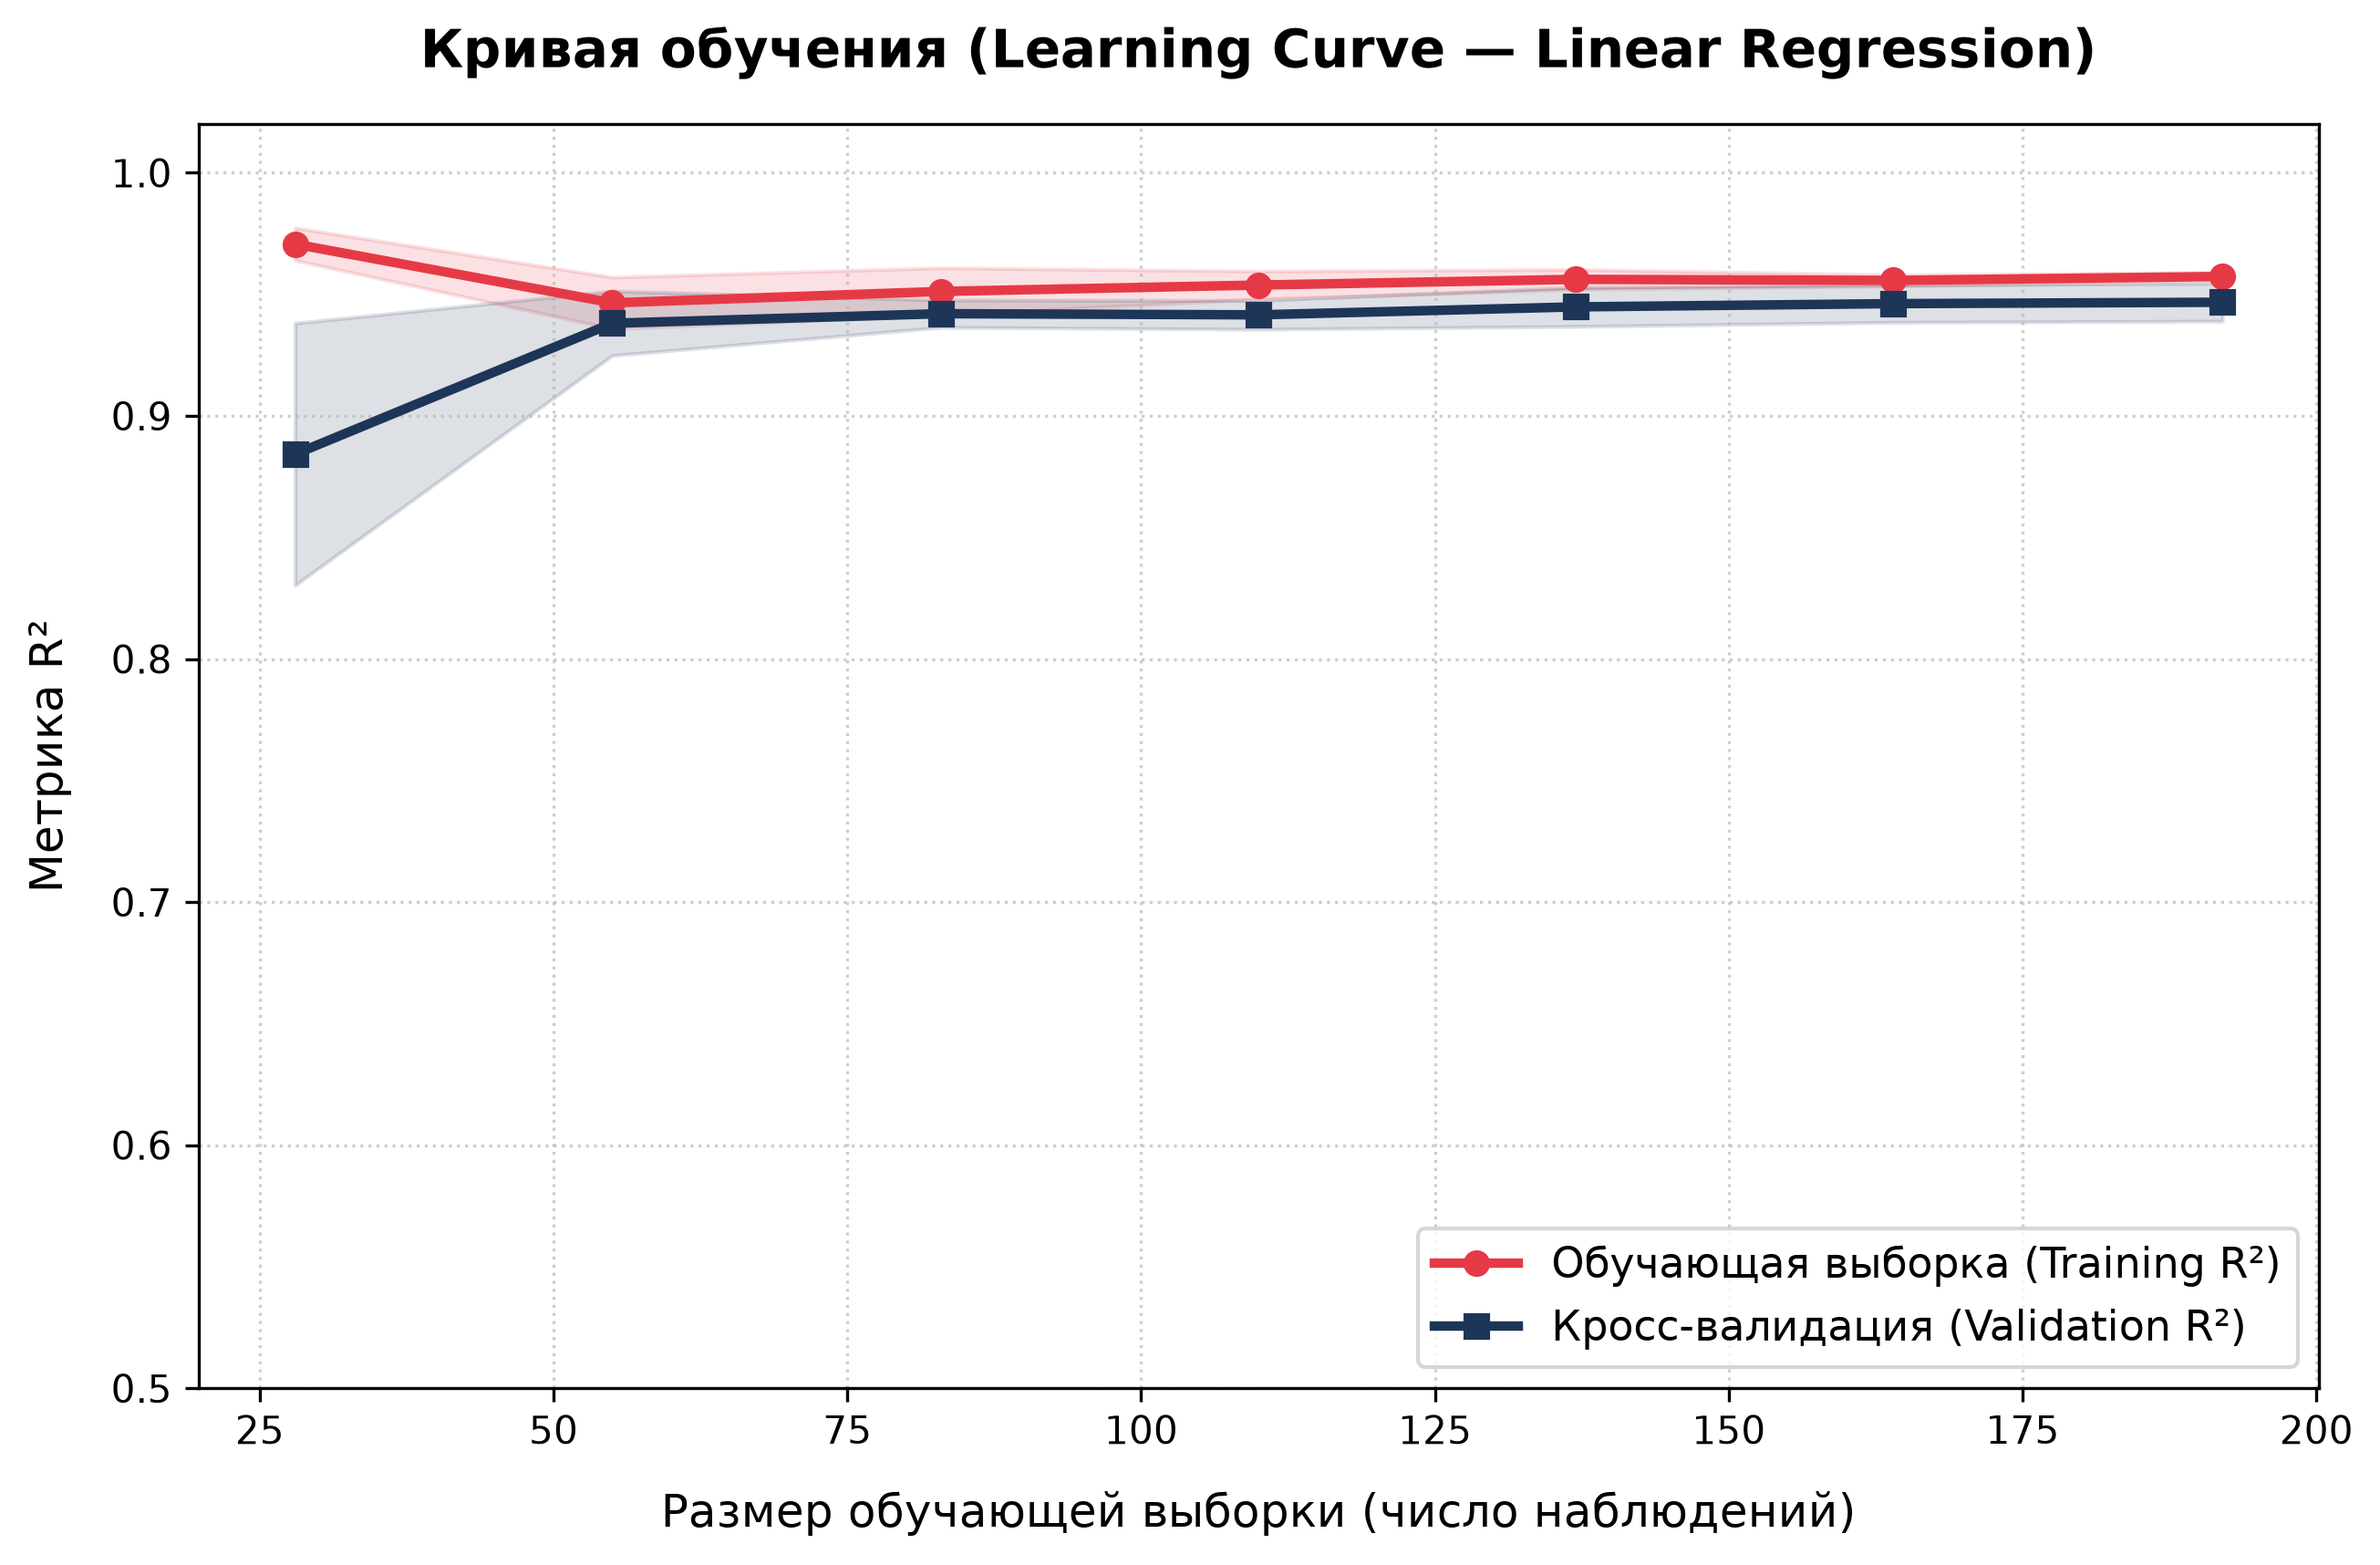

In [9]:
train_sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X_train,
    y=y_train,
    cv=5,
    scoring='r2',
    train_sizes=np.linspace(0.15, 1.0, 7),
    shuffle=True,
    random_state=42
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='#e63946', linewidth=2.5, label='Обучающая выборка (Training R²)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='#e63946')

plt.plot(train_sizes, val_mean, 's-', color='#1d3557', linewidth=2.5, label='Кросс-валидация (Validation R²)')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='#1d3557')

plt.title('Кривая обучения (Learning Curve — Linear Regression)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Размер обучающей выборки', fontsize=12)
plt.ylabel('Метрика R²', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.ylim(0.7, 1.02)
plt.show()

### 📈 Анализ кривой обучения:
1. **Динамика метрик:**
   - По мере увеличения размера обучающей выборки качество на обучении плавно стабилизируется на уровне $R^2 \approx 0.957$.
   - Качество на кросс-валидации устойчиво возрастает от $0.88$ до **$0.947$**, выходя на стабильное асимптотическое плато.
2. **Признаки переобучения:**
   - **Признаков переобучения нет.** Зазор между кривой обучения и валидационной кривой составляет всего около $0.01$, а дисперсия кросс-валидационных оценок очень низкая. Модель хорошо сбалансирована (Good Fit) и надежно обобщает данные.

---
## 6. Прогноз для новых автомобилей
Рассчитаем прогноз стоимости для 3 автомобилей по заданным характеристикам:
1. Возраст: 5, Пробег: 75 000, Объём: 1.6, Мощность: 110, Марка: Toyota, Топливо: petrol, Коробка: automatic, ДТП: no
2. Возраст: 10, Пробег: 180 000, Объём: 2.0, Мощность: 140, Марка: Hyundai, Топливо: diesel, Коробка: manual, ДТП: yes
3. Возраст: 3, Пробег: 40 000, Объём: 2.5, Мощность: 170, Марка: BMW, Топливо: petrol, Коробка: automatic, ДТП: no

In [10]:
new_cars = pd.DataFrame([
    {'age_years': 5, 'mileage_km': 75000, 'engine_l': 1.6, 'power_hp': 110, 'brand': 'Toyota', 'fuel_type': 'petrol', 'transmission': 'automatic', 'accident_history': 'no'},
    {'age_years': 10, 'mileage_km': 180000, 'engine_l': 2.0, 'power_hp': 140, 'brand': 'Hyundai', 'fuel_type': 'diesel', 'transmission': 'manual', 'accident_history': 'yes'},
    {'age_years': 3, 'mileage_km': 40000, 'engine_l': 2.5, 'power_hp': 170, 'brand': 'BMW', 'fuel_type': 'petrol', 'transmission': 'automatic', 'accident_history': 'no'}
])

# Применяем то же преобразование признаков (Feature Engineering)
new_cars['mileage_per_year'] = new_cars['mileage_km'] / new_cars['age_years']

# Прогноз через обученный Pipeline
new_cars['predicted_price_azn'] = model.predict(new_cars)

display(new_cars[['brand', 'age_years', 'mileage_km', 'engine_l', 'power_hp', 'fuel_type', 'transmission', 'accident_history', 'predicted_price_azn']].round(2))